# 03 - Iris Dataset: Complete Exploratory Analysis
**Task 1, Part G - Advanced Challenge**

The Iris dataset has 150 flowers of 3 species with 4 measurements each.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys; sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from eda_utils import missing_report, iqr_outliers, save_fig, clean_columns
sns.set_theme(style="whitegrid", palette="deep")
%matplotlib inline

## 1. Load and inspect

In [2]:
iris = pd.read_csv("../data/iris.csv")
print("Shape:", iris.shape)
iris.head(10)

Shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [3]:
iris.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [4]:
print("Missing values:", iris.isnull().sum().sum())
print("Duplicate rows:", iris.duplicated().sum())
print(iris["species"].value_counts())

Missing values: 0
Duplicate rows: 1
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 2. Clean (rename columns, drop duplicate)

In [5]:
iris = clean_columns(iris).drop_duplicates().reset_index(drop=True)
iris = iris.rename(columns={"sepal_length_cm": "sepal_length", "sepal_width_cm": "sepal_width",
                            "petal_length_cm": "petal_length", "petal_width_cm": "petal_width"})
print(iris.shape); print(list(iris.columns))

(149, 5)
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


## 3. Descriptive statistics

In [6]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
display(iris[features].describe().round(2))
display(pd.DataFrame({"median": iris[features].median(), "mode": iris[features].mode().iloc[0]}))
iris.groupby("species")[features].mean().round(2)

,sepal_length,sepal_width,petal_length,petal_width
count,149.00,149.00,149.00,149.00
mean,5.84,3.06,3.75,1.19
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.30,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


,median,mode
sepal_length,5.8,5.0
sepal_width,3.0,3.0
petal_length,4.3,1.4
petal_width,1.3,0.2


,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.60,2.98,5.56,2.03


## 4. Histograms

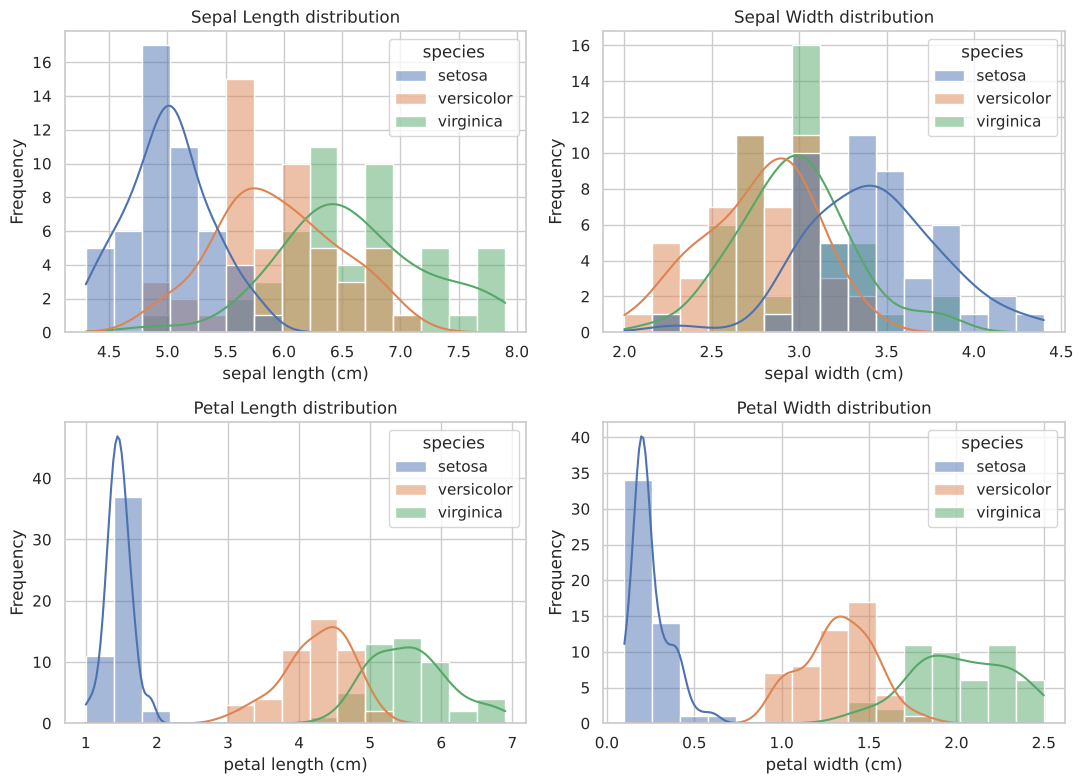

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=iris, x=col, hue="species", kde=True, ax=ax, bins=15)
    ax.set_title(f"{col.replace('_', ' ').title()} distribution"); ax.set_xlabel(col.replace("_", " ") + " (cm)"); ax.set_ylabel("Frequency")
plt.tight_layout(); save_fig("iris_histograms.png"); plt.show()

## 5. Box plots (outliers)

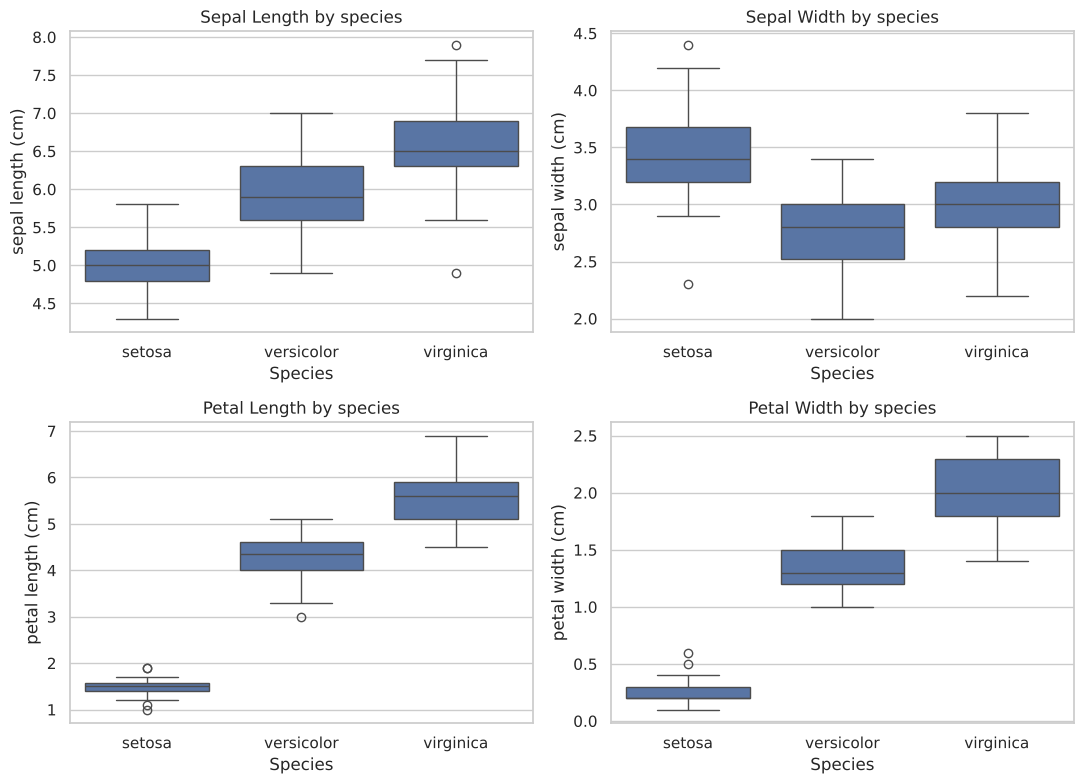

sepal_length outliers (overall): []
sepal_width outliers (overall): [4.4, 4.1, 4.2, 2.0]
petal_length outliers (overall): []
petal_width outliers (overall): []


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=iris, x="species", y=col, ax=ax)
    ax.set_title(f"{col.replace('_', ' ').title()} by species"); ax.set_xlabel("Species"); ax.set_ylabel(col.replace("_", " ") + " (cm)")
plt.tight_layout(); save_fig("iris_boxplots.png"); plt.show()
for c in features:
    print(c, "outliers (overall):", iqr_outliers(iris[c]).round(1).tolist())

## 6. Scatter plots and pair plot

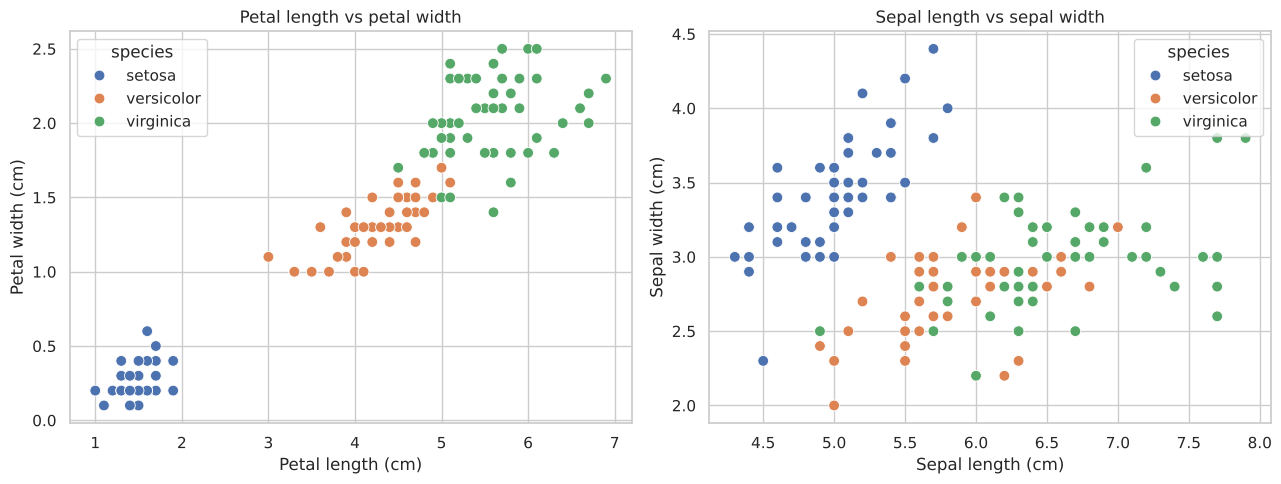

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=iris, x="petal_length", y="petal_width", hue="species", s=60, ax=axes[0])
axes[0].set_title("Petal length vs petal width"); axes[0].set_xlabel("Petal length (cm)"); axes[0].set_ylabel("Petal width (cm)")
sns.scatterplot(data=iris, x="sepal_length", y="sepal_width", hue="species", s=60, ax=axes[1])
axes[1].set_title("Sepal length vs sepal width"); axes[1].set_xlabel("Sepal length (cm)"); axes[1].set_ylabel("Sepal width (cm)")
plt.tight_layout(); save_fig("iris_scatter.png"); plt.show()

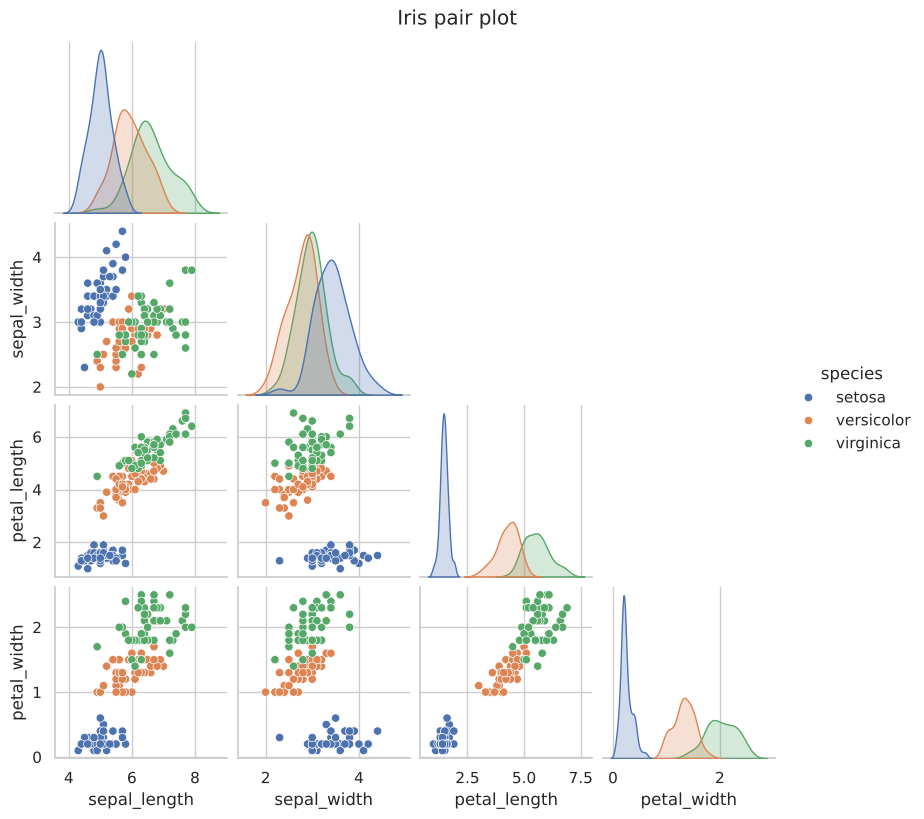

In [10]:
g = sns.pairplot(iris, hue="species", corner=True, height=2)
g.figure.suptitle("Iris pair plot", y=1.02)
g.figure.savefig("../images/iris_pairplot.png", dpi=130, bbox_inches="tight"); plt.show()

## 7. Correlation heatmap

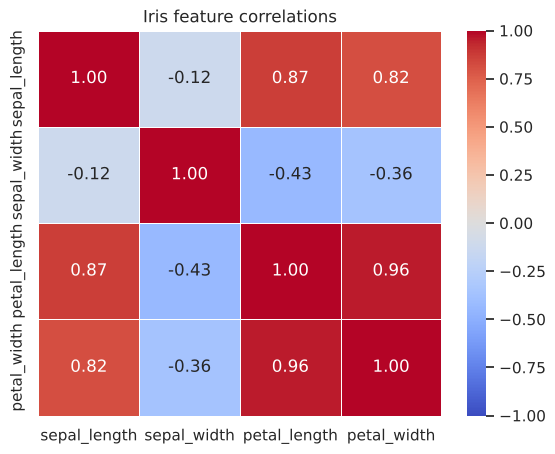

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.00,-0.12,0.87,0.82
sepal_width,-0.12,1.00,-0.43,-0.36
petal_length,0.87,-0.43,1.00,0.96
petal_width,0.82,-0.36,0.96,1.00


In [11]:
corr = iris[features].corr().round(2)
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidths=.5)
plt.title("Iris feature correlations"); save_fig("iris_correlation_heatmap.png"); plt.show()
corr

## 8. Insights (data-driven)

In [12]:
r = iris[features].corr()
means = iris.groupby("species")[features].mean()
print("1. Balanced classes: %s" % iris["species"].value_counts().to_dict())
print("2. Petal length and petal width are almost perfectly correlated (r = %.2f)." % r.loc["petal_length", "petal_width"])
print("3. Petal length also tracks sepal length strongly (r = %.2f)." % r.loc["petal_length", "sepal_length"])
print("4. Sepal width is the odd one out: weak/negative correlation with the others (r = %.2f with petal length)." % r.loc["sepal_width", "petal_length"])
print("5. Setosa is clearly separable: mean petal length %.2f cm vs %.2f (versicolor) and %.2f (virginica)." % (means.loc["setosa", "petal_length"], means.loc["versicolor", "petal_length"], means.loc["virginica", "petal_length"]))
print("6. Versicolor and virginica overlap in sepal measurements but separate well on petal measurements.")
print("7. Petal measurements are the best features for a future classifier; sepal width is the weakest.")

1. Balanced classes: {'setosa': 50, 'versicolor': 50, 'virginica': 49}
2. Petal length and petal width are almost perfectly correlated (r = 0.96).
3. Petal length also tracks sepal length strongly (r = 0.87).
4. Sepal width is the odd one out: weak/negative correlation with the others (r = -0.43 with petal length).
5. Setosa is clearly separable: mean petal length 1.46 cm vs 4.26 (versicolor) and 5.56 (virginica).
6. Versicolor and virginica overlap in sepal measurements but separate well on petal measurements.
7. Petal measurements are the best features for a future classifier; sepal width is the weakest.


### Conclusion
Petal length and width almost fully separate the three species, so even a simple model should classify Iris accurately. This motivates feature selection and baseline models in Task 2.